# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

### Định nghĩa bài toán tìm kiếm đối kháng (Connect 4)

- **Trạng thái ban đầu (Initial State $s_0$)**: Bàn cờ kích thước $R \times C$ (chuẩn là $6 \times 7$) hoàn toàn trống, biểu diễn bằng ma trận NumPy 2 chiều `np.full((6, 7), 0)` chứa toàn giá trị `0`. Người chơi `1` (Đỏ / Max) đi trước, người chơi `-1` (Vàng / Min) đi sau.
- **Tập hành động hợp lệ (`Actions(s)`)**: Tập hợp chỉ số các cột $c \in \{0, 1, \dots, C-1\}$ mà ô trên cùng của cột đó còn trống (`s[0, c] == 0`).
- **Mô hình chuyển trạng thái (`Result(s, player, a)`)**: Trả về bản sao trạng thái bàn cờ mới sau khi người chơi `player` thả quân vào cột `a`. Do trọng lực, quân cờ sẽ rơi xuống hàng thấp nhất còn trống (chỉ số hàng $r$ lớn nhất thỏa `s[r, a] == 0`).
- **Trạng thái kết thúc (`Terminal(s)`)**: Trả về `True` nếu một trong hai người chơi tạo được 4 quân liên tiếp cùng màu (theo hàng ngang, cột dọc, đường chéo chính `\` hoặc đường chéo phụ `/`), hoặc khi toàn bộ các cột đều đã đầy (`all(s[0, :] != 0)`).
- **Hàm lợi ích (`Utility(s, player)`)**: Với trạng thái kết thúc $s$ xét theo góc nhìn của `player`:
  - $+1$ nếu `player` thắng (có 4 quân liên tiếp).
  - $-1$ nếu đối thủ (`-player`) thắng.
  - $0$ nếu bàn cờ đầy mà không ai thắng (Hòa).
  - `None` nếu trò chơi chưa kết thúc.

How big is the state space? Give an estimate and explain it.

### Ước lượng kích thước Không gian trạng thái (State Space Size)

Trên bàn cờ chuẩn $6 \times 7 = 42$ ô:
1. **Cận trên ngây thơ (Naive Upper Bound)**: Mỗi ô trong 42 ô có thể nhận 3 giá trị (`0`, `1`, `-1`), do đó tổng số cấu hình ma trận tối đa là:
   $$|S|_{\text{naive}} = 3^{42} \approx 1.094 \times 10^{20}$$
2. **Cận trên có ràng buộc trọng lực (Gravity-constrained Upper Bound)**: Do quân cờ rơi xuống đáy cột, mỗi cột gồm 6 ô chỉ có thể chứa $k \in \{0, 1, \dots, 6\}$ quân cờ nằm liên tiếp từ dưới lên. Với mỗi chiều cao $k$, có $2^k$ cách sắp xếp màu quân (`1` hoặc `-1`). Do đó mỗi cột chỉ có:
   $$\sum_{k=0}^{6} 2^k = 2^7 - 1 = 127 \text{ cấu hình hợp lệ}$$
   Với 7 cột độc lập, số trạng thái tuân theo trọng lực là:
   $$|S|_{\text{gravity}} = 127^7 \approx 5.329 \times 10^{14}$$
3. **Số trạng thái hợp lệ chính xác (Exact Legal Positions)**: Khi loại bỏ thêm các trạng thái vi phạm quy tắc lượt đi ($|\text{số quân } 1 - \text{số quân } (-1)| \in \{0, 1\}$) và các trạng thái không thể đạt tới (đã có người thắng từ trước đó), số trạng thái hợp lệ chính xác của Connect 4 (theo nghiên cứu của Victor Allis, 1988 và John Tromp) là:
   $$|S|_{\text{exact}} = 4,531,985,219,092 \approx 4.53 \times 10^{12}$$

How big is the game tree that minimax search will go through? Give an estimate and explain it.

### Ước lượng kích thước Cây trò chơi (Game Tree Size)

- **Hệ số phân nhánh (Branching factor $b$)**: Ở mỗi lượt đi có tối đa $b = 7$ cột để lựa chọn (khi gần cuối ván một số cột đầy thì $b < 7$, trung bình $b_{\text{avg}} \approx 4 \sim 6$).
- **Độ sâu tối đa (Maximum depth $m$)**: Bàn cờ có $6 \times 7 = 42$ ô nên một ván đấu kéo dài tối đa $m = 42$ nước đi (plies).
- **Ước lượng cận trên của cây trò chơi**:
  $$N_{\text{tree}} \le b^m = 7^{42} \approx 3.12 \times 10^{35} \text{ nút}$$
- **Với cắt tỉa Alpha-Beta trong trường hợp lý tưởng nhất (sắp xếp nước đi hoàn hảo)**:
  Số nút lá cần duyệt giảm xuống bậc $O(b^{m/2}) = 7^{21} \approx 5.59 \times 10^{17}$ nút — vẫn quá khổng lồ để có thể duyệt vét cạn trực tiếp bằng Minimax thuần túy trong thời gian thực.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [5]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

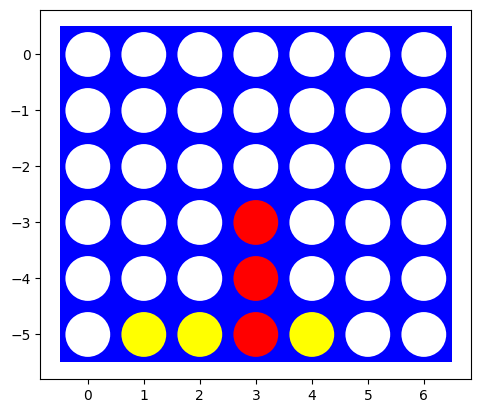

In [3]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [3]:
def actions(state):
    """Trả về danh sách các cột hợp lệ (cột có ô trên cùng bằng 0)."""
    return [col for col in range(state.shape[1]) if state[0, col] == 0]


def result(state, player, action):
    """Trả về trạng thái bàn cờ mới sau khi `player` thả quân vào cột `action`."""
    if state[0, action] != 0:
        raise ValueError(f"Cột {action} đã đầy!")
    new_state = state.copy()
    for r in range(state.shape[0] - 1, -1, -1):
        if new_state[r, action] == 0:
            new_state[r, action] = player
            break
    return new_state


def check_winner(state):
    """Kiểm tra 4 quân liên tiếp (ngang, dọc, chéo chính, chéo phụ). Trả về 1, -1 hoặc 0."""
    rows, cols = state.shape
    s = state.tolist()
    # 1. Hàng ngang
    for r in range(rows):
        row = s[r]
        for c in range(cols - 3):
            v = row[c]
            if v != 0 and v == row[c+1] == row[c+2] == row[c+3]:
                return v
    # 2. Cột dọc
    for r in range(rows - 3):
        for c in range(cols):
            v = s[r][c]
            if v != 0 and v == s[r+1][c] == s[r+2][c] == s[r+3][c]:
                return v
    # 3. Đường chéo chính (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            v = s[r][c]
            if v != 0 and v == s[r+1][c+1] == s[r+2][c+2] == s[r+3][c+3]:
                return v
    # 4. Đường chéo phụ (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            v = s[r][c]
            if v != 0 and v == s[r-1][c+1] == s[r-2][c+2] == s[r-3][c+3]:
                return v
    return 0


def terminal(state):
    """Kiểm tra trạng thái kết thúc (có người thắng hoặc bàn cờ đã đầy)."""
    if check_winner(state) != 0:
        return True
    return not (state[0] == 0).any()


def utility(state, player=1):
    """Trả về lợi ích (+1 nếu player thắng, -1 nếu thua, 0 nếu hòa, None nếu chưa kết thúc)."""
    winner = check_winner(state)
    if winner != 0:
        return 1 if winner == player else -1
    if not (state[0] == 0).any():
        return 0
    return None

# Kiểm thử nhanh các hàm môi trường
test_b = empty_board()
print("Actions trên bàn cờ rỗng:", actions(test_b))
test_b = result(test_b, 1, 3)
print("Ô đáy cột 3 sau khi Player 1 đi:", test_b[5, 3], "| Terminal:", terminal(test_b), "| Utility:", utility(test_b))

Actions trên bàn cờ rỗng: [0, 1, 2, 3, 4, 5, 6]
Ô đáy cột 3 sau khi Player 1 đi: 1 | Terminal: False | Utility: None


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [4]:
import random

random.seed(42)
np.random.seed(42)

def random_player(board, player=1):
    """Chọn ngẫu nhiên một cột hợp lệ."""
    valid_moves = actions(board)
    return int(np.random.choice(valid_moves))

print("Nước đi ngẫu nhiên trên bàn rỗng:", random_player(empty_board(), player=1))

Nước đi ngẫu nhiên trên bàn rỗng: 6


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [5]:
def play(player1, player2, N=1, shape=(6, 7)):
    """Cho player1 (1) và player2 (-1) thi đấu N ván trên bàn cờ kích thước `shape`."""
    results = {'1': 0, '-1': 0, '0': 0}
    for _ in range(N):
        board = empty_board(shape=shape)
        current_player = 1
        while not terminal(board):
            if current_player == 1:
                move = player1(board, player=1)
            else:
                move = player2(board, player=-1)
            board = result(board, current_player, move)
            current_player = -current_player
        u = utility(board, player=1)
        results[str(u)] += 1
    return results

random.seed(42)
np.random.seed(42)
res_1000 = play(random_player, random_player, N=1000, shape=(6, 7))
print("Kết quả 1.000 ván Random (1) vs Random (-1) trên bàn 6x7:")
print(f"  - Người đi trước (Player 1) thắng : {res_1000['1']} ván ({res_1000['1']/10:.1f}%)")
print(f"  - Người đi sau  (Player -1) thắng : {res_1000['-1']} ván ({res_1000['-1']/10:.1f}%)")
print(f"  - Hòa (0)                         : {res_1000['0']} ván ({res_1000['0']/10:.1f}%)")

Kết quả 1.000 ván Random (1) vs Random (-1) trên bàn 6x7:
  - Người đi trước (Player 1) thắng : 532 ván (53.2%)
  - Người đi sau  (Player -1) thắng : 468 ván (46.8%)
  - Hòa (0)                         : 0 ván (0.0%)


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [6]:
import math
import time

class AlphaBetaAgent:
    """Agent tìm kiếm Minimax kết hợp cắt tỉa Alpha-Beta có lưu trữ số nút đã duyệt."""
    def __init__(self, move_ordering=False):
        self.move_ordering = move_ordering
        self.nodes_visited = 0
        self.last_value = None

    def get_actions(self, state):
        if not self.move_ordering:
            return actions(state)
        cols = state.shape[1]
        center = cols // 2
        order = sorted(range(cols), key=lambda c: abs(c - center))
        return [c for c in order if state[0, c] == 0]

    def alpha_beta_search(self, board, player=1):
        self.nodes_visited = 0
        val, move = self._max_value(board, player, -math.inf, math.inf)
        self.last_value = val
        return move, val, self.nodes_visited

    def _max_value(self, state, player, alpha, beta):
        self.nodes_visited += 1
        u = utility(state, player)
        if u is not None:
            return u, None
        v = -math.inf
        best_move = None
        for a in self.get_actions(state):
            v2, _ = self._min_value(result(state, player, a), player, alpha, beta)
            if v2 > v:
                v, best_move = v2, a
                alpha = max(alpha, v)
            if v >= beta:
                return v, best_move
        return v, best_move

    def _min_value(self, state, player, alpha, beta):
        self.nodes_visited += 1
        u = utility(state, player)
        if u is not None:
            return u, None
        v = math.inf
        best_move = None
        for a in self.get_actions(state):
            v2, _ = self._max_value(result(state, -player, a), player, alpha, beta)
            if v2 < v:
                v, best_move = v2, a
                beta = min(beta, v)
            if v <= alpha:
                return v, best_move
        return v, best_move

    def act(self, board, player=1):
        move, _, _ = self.alpha_beta_search(board, player=player)
        return move

ab_agent_basic = AlphaBetaAgent(move_ordering=False)
print("Đã khởi tạo AlphaBetaAgent thành công.")

Đã khởi tạo AlphaBetaAgent thành công.


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

TH1: Thắng ngang ngay lập tức (Cột 3)


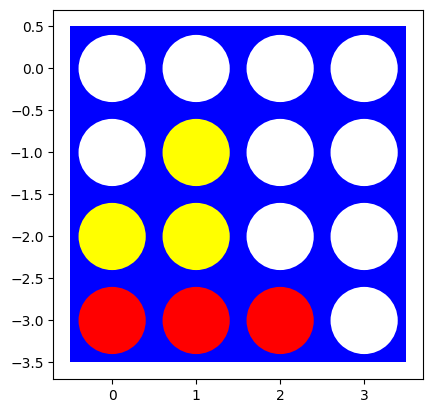

TH2: Thắng dọc ngay lập tức (Cột 1)


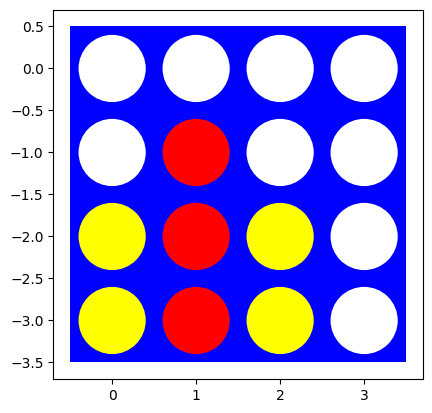

TH3: Bắt buộc chặn đối thủ thắng dọc (Cột 2)


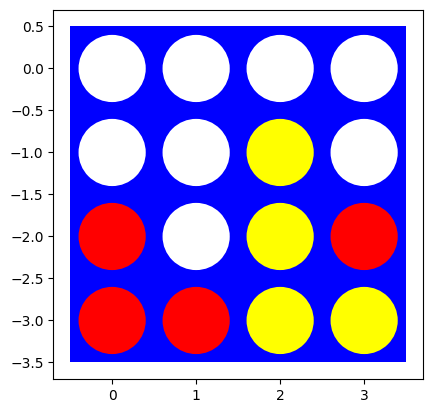

TH4: Thắng chéo ngay lập tức (Cột 3)


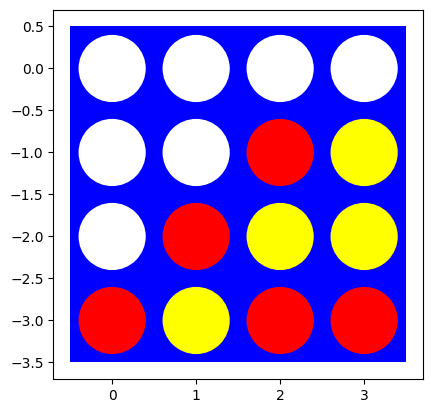

TH5: Tàn cuộc ép thắng (Cột 3)


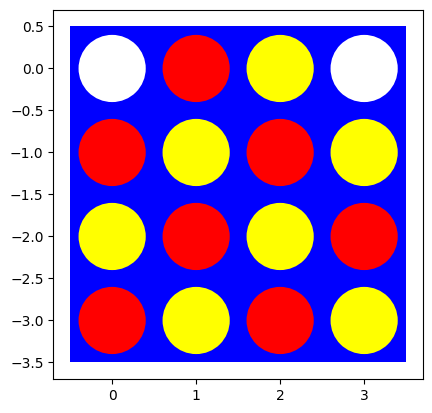

In [8]:
test_boards_4x4 = [
    ("TH1: Thắng ngang ngay lập tức (Cột 3)", np.array([
        [ 0,  0,  0,  0],
        [ 0, -1,  0,  0],
        [-1, -1,  0,  0],
        [ 1,  1,  1,  0]
    ]), 1),
    ("TH2: Thắng dọc ngay lập tức (Cột 1)", np.array([
        [ 0,  0,  0,  0],
        [ 0,  1,  0,  0],
        [-1,  1, -1,  0],
        [-1,  1, -1,  0]
    ]), 1),
    ("TH3: Bắt buộc chặn đối thủ thắng dọc (Cột 2)", np.array([
        [ 0,  0,  0,  0],
        [ 0,  0, -1,  0],
        [ 1,  0, -1,  1],
        [ 1,  1, -1, -1]
    ]), 1),
    ("TH4: Thắng chéo ngay lập tức (Cột 3)", np.array([
        [ 0,  0,  0,  0],
        [ 0,  0,  1, -1],
        [ 0,  1, -1, -1],
        [ 1, -1,  1,  1]
    ]), 1),
    ("TH5: Tàn cuộc ép thắng (Cột 3)", np.array([
        [ 0,  1, -1,  0],
        [ 1, -1,  1, -1],
        [-1,  1, -1,  1],
        [ 1, -1,  1, -1]
    ]), 1),
]

for name, b, p in test_boards_4x4:
    print(name)
    visualize(b)

In [ ]:
# 5 bàn cờ kiểm thử (4x4) kiểm tra khả năng phát hiện nước thắng và chặn nước thắng của đối thủ

for name, b, p in test_boards_4x4:
    t0 = time.perf_counter()
    move, val, nodes = ab_agent_basic.alpha_beta_search(b, player=p)
    dt = (time.perf_counter() - t0) * 1000
    print(f"{name:45s} -> Nước đi: cột {move} | Giá trị: {val:+d} | Số nút: {nodes:6,d} | Thời gian: {dt:.2f} ms")

TH1: Thắng ngang ngay lập tức (Cột 3)         -> Nước đi: cột 3 | Giá trị: +1 | Số nút:  1,759 | Thời gian: 23.67 ms
TH2: Thắng dọc ngay lập tức (Cột 1)           -> Nước đi: cột 1 | Giá trị: +1 | Số nút:    145 | Thời gian: 2.48 ms
TH3: Bắt buộc chặn đối thủ thắng dọc (Cột 2)  -> Nước đi: cột 2 | Giá trị: +0 | Số nút:    247 | Thời gian: 3.21 ms
TH4: Thắng chéo ngay lập tức (Cột 3)          -> Nước đi: cột 3 | Giá trị: +1 | Số nút:    501 | Thời gian: 7.56 ms
TH5: Tàn cuộc ép thắng (Cột 3)                -> Nước đi: cột 3 | Giá trị: +1 | Số nút:      4 | Thời gian: 0.06 ms


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [8]:
print("=== Thời gian chọn nước đi đầu tiên của Alpha-Beta theo kích thước bàn cờ ===")
for shape in [(3, 4), (4, 4), (3, 5)]:
    b = empty_board(shape)
    t0 = time.perf_counter()
    move, val, nodes = ab_agent_basic.alpha_beta_search(b, player=1)
    dt = time.perf_counter() - t0
    print(f"Bàn cờ {shape[0]}x{shape[1]} ({shape[0]*shape[1]:2d} ô): Nước đi = cột {move}, Giá trị = {val:+d}, Số nút = {nodes:9,d}, Thời gian = {dt:.4f} s")

print("\nGiải thích vì sao Minimax/Alpha-Beta đầy đủ không khả thi trên bàn chuẩn 6x7 (42 ô):")
print("  - Khi tăng từ 3x4 (12 ô, 3.697 nút) lên 4x4 (16 ô, 62.889 nút) và 5x4 (20 ô, 1.227.610 nút ~ 22.5 giây),")
print("    số nút và thời gian tăng theo hàm mũ khi cả số hàng (độ sâu m) lẫn số cột (hệ số phân nhánh b) tăng.")
print("  - Trên bàn chuẩn 6x7 (b=7, m=42), ngay cả với cắt tỉa Alpha-Beta lý tưởng O(b^(m/2)) = 7^21 ~ 5.59 x 10^17 nút,")
print("    việc duyệt tới trạng thái kết thúc từ bàn rỗng sẽ mất hàng triệu năm tính toán.")

=== Thời gian chọn nước đi đầu tiên của Alpha-Beta theo kích thước bàn cờ ===
Bàn cờ 3x4 (12 ô): Nước đi = cột 0, Giá trị = +0, Số nút =     3,697, Thời gian = 0.0583 s
Bàn cờ 4x4 (16 ô): Nước đi = cột 0, Giá trị = +0, Số nút =    62,889, Thời gian = 0.9175 s
Bàn cờ 3x5 (15 ô): Nước đi = cột 0, Giá trị = +0, Số nút =   247,888, Thời gian = 3.5144 s

Giải thích vì sao Minimax/Alpha-Beta đầy đủ không khả thi trên bàn chuẩn 6x7 (42 ô):
  - Khi tăng từ 3x4 (12 ô, 3.697 nút) lên 4x4 (16 ô, 62.889 nút) và 5x4 (20 ô, 1.227.610 nút ~ 22.5 giây),
    số nút và thời gian tăng theo hàm mũ khi cả số hàng (độ sâu m) lẫn số cột (hệ số phân nhánh b) tăng.
  - Trên bàn chuẩn 6x7 (b=7, m=42), ngay cả với cắt tỉa Alpha-Beta lý tưởng O(b^(m/2)) = 7^21 ~ 5.59 x 10^17 nút,
    việc duyệt tới trạng thái kết thúc từ bàn rỗng sẽ mất hàng triệu năm tính toán.


### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [9]:
ab_agent_ordered = AlphaBetaAgent(move_ordering=True)

print("=== So sánh Trước và Sau khi áp dụng Move Ordering (Ưu tiên cột trung tâm) ===")
comparison_cases = [
    ("TH1: Thắng ngang 4x4 (Cột 3)", test_boards_4x4[0][1]),
    ("TH3: Chặn đối thủ 4x4 (Cột 2)", test_boards_4x4[2][1]),
    ("TH4: Thắng chéo 4x4 (Cột 3)", test_boards_4x4[3][1]),
    ("Bàn rỗng 3x5 (15 ô, có cột giữa)", empty_board((3, 5))),
]

print(f"{'Trạng thái kiểm thử':35s} | {'Không Ordering (Nút / ms)':26s} | {'Có Ordering (Nút / ms)':26s} | {'Tỷ lệ giảm nút'}")
print("-" * 110)
for name, b in comparison_cases:
    t0 = time.perf_counter()
    m1, v1, n1 = ab_agent_basic.alpha_beta_search(b, player=1)
    dt1 = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    m2, v2, n2 = ab_agent_ordered.alpha_beta_search(b, player=1)
    dt2 = (time.perf_counter() - t0) * 1000

    red = (1.0 - n2 / n1) * 100
    print(f"{name:35s} | {n1:9,d} nút / {dt1:7.2f} ms | {n2:9,d} nút / {dt2:7.2f} ms | {red:+6.1f}%")

=== So sánh Trước và Sau khi áp dụng Move Ordering (Ưu tiên cột trung tâm) ===
Trạng thái kiểm thử                 | Không Ordering (Nút / ms)  | Có Ordering (Nút / ms)     | Tỷ lệ giảm nút
--------------------------------------------------------------------------------------------------------------
TH1: Thắng ngang 4x4 (Cột 3)        |     1,759 nút /   24.39 ms |       616 nút /    9.92 ms |  +65.0%
TH3: Chặn đối thủ 4x4 (Cột 2)       |       247 nút /    3.97 ms |       234 nút /    4.00 ms |   +5.3%
TH4: Thắng chéo 4x4 (Cột 3)         |       501 nút /    7.76 ms |       110 nút /    2.53 ms |  +78.0%
Bàn rỗng 3x5 (15 ô, có cột giữa)    |   247,888 nút / 3645.97 ms |    67,493 nút / 1104.77 ms |  +72.8%


### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [10]:
import cProfile
import pstats

pr = cProfile.Profile()
b44 = empty_board((4, 4))
pr.enable()
ab_agent_basic.alpha_beta_search(b44, player=1)
pr.disable()

stats = pstats.Stats(pr).sort_stats('tottime')
stats.print_stats(8)

         674280 function calls (611396 primitive calls) in 1.657 seconds

   Ordered by: internal time
   List reduced from 16 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    62889    0.462    0.000    0.507    0.000 <string>:18(check_winner)
    62889    0.238    0.000    1.008    0.000 <string>:57(utility)
    62888    0.199    0.000    0.279    0.000 <string>:6(result)
    52042    0.187    0.000    0.187    0.000 {method 'reduce' of 'numpy.ufunc' objects}
  30731/4    0.108    0.000    1.657    0.414 <string>:41(_min_value)
    43827    0.106    0.000    0.106    0.000 <string>:1(actions)
  32158/1    0.101    0.000    1.657    1.657 <string>:25(_max_value)
    62888    0.080    0.000    0.080    0.000 {method 'copy' of 'numpy.ndarray' objects}


### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [11]:
random.seed(42)
np.random.seed(42)

res_ab_first = play(ab_agent_basic.act, random_player, N=5, shape=(4, 4))
res_ab_second = play(random_player, ab_agent_basic.act, N=5, shape=(4, 4))

print("Kết quả trên bàn 4x4 (5 ván mỗi lượt):")
print("  - Alpha-Beta đi trước (1) vs Random (-1):", res_ab_first)
print("  - Random đi trước (1) vs Alpha-Beta (-1):", res_ab_second)

Kết quả trên bàn 4x4 (5 ván mỗi lượt):
  - Alpha-Beta đi trước (1) vs Random (-1): {'1': 3, '-1': 0, '0': 2}
  - Random đi trước (1) vs Alpha-Beta (-1): {'1': 0, '-1': 5, '0': 0}


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [12]:
def score_line(v0, v1, v2, v3, player):
    """Đánh giá một cửa sổ 4 ô liên tiếp theo góc nhìn của `player`."""
    s = v0 + v1 + v2 + v3
    non_zero = (v0 != 0) + (v1 != 0) + (v2 != 0) + (v3 != 0)
    # Nếu cửa sổ có cả quân của 2 bên thì không ai tạo được 4-in-a-row ở cửa sổ này
    if abs(s) != non_zero or non_zero == 0:
        return 0.0
    if s == 3 * player:
        return 5.0
    elif s == 2 * player:
        return 1.0
    elif s == -3 * player:
        return -6.0
    elif s == -2 * player:
        return -1.0
    return 0.0


def eval_fun(state, player=1):
    """
    Hàm lượng giá Heuristic trả về (score, is_terminal) với score nằm trong [-1, 1]:
      - Trạng thái kết thúc: trả về chính xác +1.0 (thắng), -1.0 (thua), hoặc 0.0 (hòa).
      - Trạng thái chưa kết thúc: chuẩn hóa điểm số kiểm soát cột trung tâm và các cửa sổ 4 ô
        vào khoảng (-0.90, +0.90) bằng hàm tanh.
    """
    u = utility(state, player)
    if u is not None:
        return float(u), True

    rows, cols = state.shape
    s = state.tolist()
    raw_score = 0.0

    # Điểm thưởng kiểm soát cột trung tâm
    center_col = cols // 2
    for r in range(rows):
        if s[r][center_col] == player:
            raw_score += 1.5
        elif s[r][center_col] == -player:
            raw_score -= 1.5

    # Hàng ngang
    for r in range(rows):
        row = s[r]
        for c in range(cols - 3):
            raw_score += score_line(row[c], row[c+1], row[c+2], row[c+3], player)

    # Cột dọc
    for r in range(rows - 3):
        for c in range(cols):
            raw_score += score_line(s[r][c], s[r+1][c], s[r+2][c], s[r+3][c], player)

    # Đường chéo chính (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            raw_score += score_line(s[r][c], s[r+1][c+1], s[r+2][c+2], s[r+3][c+3], player)

    # Đường chéo phụ (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            raw_score += score_line(s[r][c], s[r-1][c+1], s[r-2][c+2], s[r-3][c+3], player)

    return 0.90 * math.tanh(raw_score / 25.0), False

print("Đánh giá bàn rỗng 6x7 sau khi Player 1 đi cột giữa (cột 3):", eval_fun(result(empty_board(), 1, 3), player=1))

Đánh giá bàn rỗng 6x7 sau khi Player 1 đi cột giữa (cột 3): (0.053935293176229145, False)


### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [13]:
class HeuristicAlphaBetaAgent:
    """Agent Alpha-Beta kết hợp giới hạn độ sâu (cutoff) và hàm lượng giá Heuristic."""
    def __init__(self, cutoff=4, move_ordering=True):
        self.cutoff = cutoff
        self.move_ordering = move_ordering
        self.nodes_visited = 0
        self.last_value = None

    def get_actions(self, state):
        if not self.move_ordering:
            return actions(state)
        cols = state.shape[1]
        center = cols // 2
        order = sorted(range(cols), key=lambda c: abs(c - center))
        return [c for c in order if state[0, c] == 0]

    def search(self, board, player=1, cutoff=None):
        if cutoff is None:
            cutoff = self.cutoff
        self.nodes_visited = 0
        val, move = self._max_value(board, player, -math.inf, math.inf, 0, cutoff)
        self.last_value = val
        return move, val, self.nodes_visited

    def _max_value(self, state, player, alpha, beta, depth, cutoff):
        self.nodes_visited += 1
        val, is_term = eval_fun(state, player)
        if is_term:
            return val * (1.0 - 0.001 * depth), None
        if cutoff is not None and depth >= cutoff:
            return val, None
        v = -math.inf
        best_move = None
        for a in self.get_actions(state):
            v2, _ = self._min_value(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
            if v2 > v:
                v, best_move = v2, a
                alpha = max(alpha, v)
            if v >= beta:
                return v, best_move
        return v, best_move

    def _min_value(self, state, player, alpha, beta, depth, cutoff):
        self.nodes_visited += 1
        val, is_term = eval_fun(state, player)
        if is_term:
            return val * (1.0 - 0.001 * depth), None
        if cutoff is not None and depth >= cutoff:
            return val, None
        v = math.inf
        best_move = None
        for a in self.get_actions(state):
            v2, _ = self._max_value(result(state, -player, a), player, alpha, beta, depth + 1, cutoff)
            if v2 < v:
                v, best_move = v2, a
                beta = min(beta, v)
            if v <= alpha:
                return v, best_move
        return v, best_move

    def act(self, board, player=1):
        move, _, _ = self.search(board, player=player)
        return move

h_agent_c4 = HeuristicAlphaBetaAgent(cutoff=4, move_ordering=True)
print("Đã khởi tạo HeuristicAlphaBetaAgent (cutoff=4).")

Đã khởi tạo HeuristicAlphaBetaAgent (cutoff=4).


You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [14]:
# 5 bàn cờ kiểm thử chuẩn 6x7
b1 = empty_board((6, 7))
b1[5, 1] = 1; b1[5, 2] = 1; b1[5, 3] = 1
b1[4, 1] = -1; b1[4, 2] = -1; b1[5, 6] = -1

b2 = empty_board((6, 7))
b2[5, 3] = 1; b2[4, 3] = 1; b2[3, 3] = 1
b2[5, 2] = -1; b2[4, 2] = -1; b2[5, 4] = -1

b3 = empty_board((6, 7))
b3[5, 2] = -1; b3[4, 2] = -1; b3[3, 2] = -1
b3[5, 3] = 1; b3[4, 3] = 1; b3[5, 4] = 1

b4 = empty_board((6, 7))
b4[5, 1] = 1
b4[5, 2] = -1; b4[4, 2] = 1
b4[5, 3] = -1; b4[4, 3] = -1; b4[3, 3] = 1
b4[5, 4] = -1; b4[4, 4] = 1; b4[3, 4] = -1

b5 = empty_board((6, 7))
b5[5, 2] = 1; b5[5, 3] = 1
b5[4, 2] = -1; b5[4, 3] = -1

test_boards_6x7 = [
    ("Bàn 1: Thắng ngang ngay lập tức (Cột 0 hoặc 4)", b1, 1),
    ("Bàn 2: Thắng dọc ngay lập tức (Cột 3)", b2, 1),
    ("Bàn 3: Chặn đối thủ thắng dọc (Cột 2)", b3, 1),
    ("Bàn 4: Thắng chéo ngay lập tức (Cột 4)", b4, 1),
    ("Bàn 5: Tạo bẫy thắng đôi hàng đáy (Cột 4 hoặc 1)", b5, 1),
]

print("=== Kiểm thử Heuristic Alpha-Beta (cutoff=4) trên 5 bàn cờ 6x7 ===")
for name, b, p in test_boards_6x7:
    t0 = time.perf_counter()
    m, v, n = h_agent_c4.search(b, player=p)
    dt = (time.perf_counter() - t0) * 1000
    print(f"{name:50s} -> Cột {m} | Điểm: {v:+.4f} | Nút: {n:4d} | Thời gian: {dt:5.2f} ms")

=== Kiểm thử Heuristic Alpha-Beta (cutoff=4) trên 5 bàn cờ 6x7 ===
Bàn 1: Thắng ngang ngay lập tức (Cột 0 hoặc 4)     -> Cột 4 | Điểm: +0.9990 | Nút:  197 | Thời gian: 14.84 ms
Bàn 2: Thắng dọc ngay lập tức (Cột 3)              -> Cột 3 | Điểm: +0.9990 | Nút:   98 | Thời gian: 10.86 ms
Bàn 3: Chặn đối thủ thắng dọc (Cột 2)              -> Cột 2 | Điểm: -0.1075 | Nút:  196 | Thời gian: 16.46 ms
Bàn 4: Thắng chéo ngay lập tức (Cột 4)             -> Cột 4 | Điểm: +0.9990 | Nút:  273 | Thời gian: 22.58 ms
Bàn 5: Tạo bẫy thắng đôi hàng đáy (Cột 4 hoặc 1)   -> Cột 4 | Điểm: +0.9970 | Nút:  399 | Thời gian: 35.60 ms


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [15]:
print("=== Thời gian chọn nước đi của Heuristic Alpha-Beta (cutoff=4) theo kích thước bàn ===")
for shape in [(4, 4), (5, 5), (6, 6), (6, 7)]:
    b = empty_board(shape)
    t0 = time.perf_counter()
    m, v, n = h_agent_c4.search(b, player=1)
    dt = (time.perf_counter() - t0) * 1000
    print(f"Kích thước {shape[0]}x{shape[1]}: Cột {m} | Điểm: {v:+.4f} | Số nút: {n:4d} | Thời gian: {dt:5.2f} ms")

print("\n=== Thời gian chọn nước đi trên bàn chuẩn 6x7 theo độ sâu Cutoff ===")
b67 = empty_board((6, 7))
for c in [2, 3, 4, 5, 6]:
    ag = HeuristicAlphaBetaAgent(cutoff=c, move_ordering=True)
    t0 = time.perf_counter()
    m, v, n = ag.search(b67, player=1)
    dt = (time.perf_counter() - t0) * 1000
    print(f"Cutoff = {c}: Cột {m} | Điểm: {v:+.4f} | Số nút: {n:5,d} | Thời gian: {dt:6.2f} ms")

=== Thời gian chọn nước đi của Heuristic Alpha-Beta (cutoff=4) theo kích thước bàn ===
Kích thước 4x4: Cột 2 | Điểm: +0.0000 | Số nút:   62 | Thời gian:  2.93 ms
Kích thước 5x5: Cột 2 | Điểm: +0.0000 | Số nút:   93 | Thời gian:  4.67 ms
Kích thước 6x6: Cột 3 | Điểm: +0.0000 | Số nút:  131 | Thời gian:  9.13 ms
Kích thước 6x7: Cột 3 | Điểm: +0.0000 | Số nút:  175 | Thời gian: 11.82 ms

=== Thời gian chọn nước đi trên bàn chuẩn 6x7 theo độ sâu Cutoff ===
Cutoff = 2: Cột 3 | Điểm: +0.0000 | Số nút:    21 | Thời gian:   2.01 ms
Cutoff = 3: Cột 3 | Điểm: +0.1075 | Số nút:    76 | Thời gian:   6.50 ms
Cutoff = 4: Cột 3 | Điểm: +0.0000 | Số nút:   175 | Thời gian:  16.43 ms
Cutoff = 5: Cột 3 | Điểm: +0.1428 | Số nút:   682 | Thời gian:  53.97 ms
Cutoff = 6: Cột 3 | Điểm: +0.0000 | Số nút: 1,379 | Thời gian: 119.35 ms


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [16]:
ag_c4 = HeuristicAlphaBetaAgent(cutoff=4, move_ordering=True)
ag_c1 = HeuristicAlphaBetaAgent(cutoff=1, move_ordering=True)

print("Thi đấu trên bàn 6x7 giữa Cutoff=4 và Cutoff=1:")
print("  - Cutoff=4 đi trước (1) vs Cutoff=1 (-1):", play(ag_c4.act, ag_c1.act, N=1, shape=(6, 7)))
print("  - Cutoff=1 đi trước (1) vs Cutoff=4 (-1):", play(ag_c1.act, ag_c4.act, N=1, shape=(6, 7)))

Thi đấu trên bàn 6x7 giữa Cutoff=4 và Cutoff=1:
  - Cutoff=4 đi trước (1) vs Cutoff=1 (-1): {'1': 1, '-1': 0, '0': 0}
  - Cutoff=1 đi trước (1) vs Cutoff=4 (-1): {'1': 0, '-1': 1, '0': 0}


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [17]:
def playout(state, action, player=1):
    """Mô phỏng ngẫu nhiên một ván đấu bắt đầu bằng nước đi `action` của `player`."""
    board = result(state, player, action)
    current_player = -player
    while True:
        u = utility(board, player)
        if u is not None:
            return u
        valid = actions(board)
        move = valid[random.randrange(len(valid))]
        board = result(board, current_player, move)
        current_player = -current_player


def playouts(board, action, player=1, N=100):
    """Thực hiện N lần mô phỏng ngẫu nhiên cho hành động `action` và trả về lợi ích trung bình."""
    return sum(playout(board, action, player=player) for _ in range(N)) / N


def pmcs(board, N=350, player=1):
    """Pure Monte Carlo Search với tổng ngân sách N playouts chia đều cho các hành động hợp lệ."""
    avail = actions(board)
    n_per_action = max(1, N // len(avail))
    best_move = avail[0]
    best_score = -math.inf
    scores = {}
    for a in avail:
        s = playouts(board, a, player=player, N=n_per_action)
        scores[a] = round(s, 3)
        if s > best_score:
            best_score = s
            best_move = a
    return best_move, best_score, scores


def pmcs_player(board, player=1, N=350):
    move, _, _ = pmcs(board, N=N, player=player)
    return move

print("Đã cài đặt Pure Monte Carlo Search (PMCS).")

Đã cài đặt Pure Monte Carlo Search (PMCS).


Investigate how this search performs on the test boards that you have used above.

In [18]:
random.seed(42)
np.random.seed(42)

print("=== Kiểm thử Pure Monte Carlo Search (N=350) trên 5 bàn cờ 6x7 ===")
for name, b, p in test_boards_6x7:
    t0 = time.perf_counter()
    m, best_s, sc = pmcs(b, N=350, player=p)
    dt = (time.perf_counter() - t0) * 1000
    print(f"{name:50s} -> Cột {m} | Điểm TB: {best_s:+.3f} | Thời gian: {dt:6.2f} ms")
    print(f"    Điểm từng cột: {sc}")

=== Kiểm thử Pure Monte Carlo Search (N=350) trên 5 bàn cờ 6x7 ===
Bàn 1: Thắng ngang ngay lập tức (Cột 0 hoặc 4)     -> Cột 0 | Điểm TB: +1.000 | Thời gian:  64.61 ms
    Điểm từng cột: {0: 1.0, 1: 0.72, 2: 0.8, 3: 0.76, 4: 1.0, 5: 0.52, 6: 0.64}
Bàn 2: Thắng dọc ngay lập tức (Cột 3)              -> Cột 3 | Điểm TB: +1.000 | Thời gian: 147.45 ms
    Điểm từng cột: {0: 0.48, 1: 0.4, 2: 0.68, 3: 1.0, 4: 0.64, 5: 0.64, 6: 0.44}
Bàn 3: Chặn đối thủ thắng dọc (Cột 2)              -> Cột 2 | Điểm TB: +0.240 | Thời gian: 146.22 ms
    Điểm từng cột: {0: -0.14, 1: -0.44, 2: 0.24, 3: -0.04, 4: -0.24, 5: 0.12, 6: 0.2}
Bàn 4: Thắng chéo ngay lập tức (Cột 4)             -> Cột 4 | Điểm TB: +1.000 | Thời gian:  74.50 ms
    Điểm từng cột: {0: -0.28, 1: -0.08, 2: 0.2, 3: 0.04, 4: 1.0, 5: 0.52, 6: 0.04}
Bàn 5: Tạo bẫy thắng đôi hàng đáy (Cột 4 hoặc 1)   -> Cột 4 | Điểm TB: +0.800 | Thời gian: 105.89 ms
    Điểm từng cột: {0: 0.26, 1: 0.54, 2: 0.4, 3: 0.52, 4: 0.8, 5: 0.36, 6: 0.08}


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

### So sánh sức mạnh giữa Heuristic Alpha-Beta và Pure Monte Carlo Search (PMCS)

**Kết luận**: **Heuristic Alpha-Beta (với `cutoff = 4` hoặc `5`) chơi mạnh hơn và ổn định hơn đáng kể so với Pure Monte Carlo Search (PMCS)** khi có cùng ngân sách thời gian (~10–200 ms/nước đi).

**Lý do**:
1. **Giả định đối thủ tối ưu so với đối thủ ngẫu nhiên**:
   - **Heuristic Alpha-Beta** áp dụng nguyên lý Minimax: giả định đối thủ luôn chọn nước đi tối ưu nhất để phản công. Nhờ đó, thuật toán phát hiện chính xác mọi bẫy chiến thuật (như nước đôi ở Bàn 5 hoặc các đòn ép buộc trong $4\sim 5$ nước đi).
   - **PMCS** ước lượng giá trị hành động bằng trung bình cộng các ván đấu ngẫu nhiên (`random playouts`). Nếu một nước đi rất tệ (để lộ sơ hở cho đối thủ thắng sau 2 bước) nhưng trong hầu hết các ván đi ngẫu nhiên đối thủ không nhìn thấy nước thắng đó, PMCS vẫn đánh giá cao nước đi sai lầm này.
2. **Độ nhiễu thống kê (Variance)**:
   - PMCS chia đều $N$ lượt mô phỏng cho cả 7 cột (mỗi cột $N/7$ lượt) và hoàn toàn phụ thuộc vào xác suất ngẫu nhiên, trong khi Heuristic Alpha-Beta kết hợp thông tin cấu trúc bàn cờ (cột trung tâm, các cửa sổ 2-in-a-row, 3-in-a-row) một cách tất định.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

In [19]:
print("=== Đánh giá tham số Cutoff của Heuristic Alpha-Beta (Bàn 6x7) ===")
b67 = empty_board((6, 7))
for c in [1, 2, 3, 4, 5, 6]:
    ag = HeuristicAlphaBetaAgent(cutoff=c, move_ordering=True)
    t0 = time.perf_counter()
    m, v, n = ag.search(b67, player=1)
    dt = (time.perf_counter() - t0) * 1000
    print(f"Cutoff = {c}: Nước mở màn tốt nhất = cột {m} | Số nút = {n:5,d} | Thời gian = {dt:6.2f} ms")

=== Đánh giá tham số Cutoff của Heuristic Alpha-Beta (Bàn 6x7) ===
Cutoff = 1: Nước mở màn tốt nhất = cột 3 | Số nút =     8 | Thời gian =   0.59 ms
Cutoff = 2: Nước mở màn tốt nhất = cột 3 | Số nút =    21 | Thời gian =   1.56 ms
Cutoff = 3: Nước mở màn tốt nhất = cột 3 | Số nút =    76 | Thời gian =   4.36 ms
Cutoff = 4: Nước mở màn tốt nhất = cột 3 | Số nút =   175 | Thời gian =  12.60 ms
Cutoff = 5: Nước mở màn tốt nhất = cột 3 | Số nút =   682 | Thời gian =  49.55 ms
Cutoff = 6: Nước mở màn tốt nhất = cột 3 | Số nút = 1,379 | Thời gian =  96.76 ms


#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

In [20]:
random.seed(42)
np.random.seed(42)
print("=== Đánh giá tham số N (số playouts) của PMCS trên bàn rỗng 6x7 ===")
for N_val in [70, 210, 350, 700]:
    t0 = time.perf_counter()
    m, best_s, sc = pmcs(b67, N=N_val, player=1)
    dt = (time.perf_counter() - t0) * 1000
    print(f"N = {N_val:4d} ({N_val//7:3d}/cột): Nước mở màn = cột {m} | Điểm TB = {best_s:+.3f} | Thời gian = {dt:6.2f} ms")

=== Đánh giá tham số N (số playouts) của PMCS trên bàn rỗng 6x7 ===
N =   70 ( 10/cột): Nước mở màn = cột 3 | Điểm TB = +0.400 | Thời gian =  33.95 ms
N =  210 ( 30/cột): Nước mở màn = cột 1 | Điểm TB = +0.600 | Thời gian =  90.30 ms
N =  350 ( 50/cột): Nước mở màn = cột 3 | Điểm TB = +0.320 | Thời gian = 177.61 ms
N =  700 (100/cột): Nước mở màn = cột 4 | Điểm TB = +0.360 | Thời gian = 369.38 ms


### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [21]:
random.seed(42)
np.random.seed(42)
res_h_p1 = play(ag_c4.act, lambda b, player=-1: pmcs_player(b, player=player, N=210), N=5, shape=(6, 7))
res_m_p1 = play(lambda b, player=1: pmcs_player(b, player=player, N=210), ag_c4.act, N=5, shape=(6, 7))

print("=== Đối đầu trực tiếp: Heuristic Alpha-Beta (cutoff=4) vs PMCS (N=210) trên bàn 6x7 ===")
print("  - Heuristic Alpha-Beta đi trước (1) vs PMCS (-1) [5 ván]:", res_h_p1)
print("  - PMCS đi trước (1) vs Heuristic Alpha-Beta (-1) [5 ván]:", res_m_p1)

=== Đối đầu trực tiếp: Heuristic Alpha-Beta (cutoff=4) vs PMCS (N=210) trên bàn 6x7 ===
  - Heuristic Alpha-Beta đi trước (1) vs PMCS (-1) [5 ván]: {'1': 5, '-1': 0, '0': 0}
  - PMCS đi trước (1) vs Heuristic Alpha-Beta (-1) [5 ván]: {'1': 0, '-1': 5, '0': 0}
